# Answer the questions from the Preamble and Introduction

### a. Derive the formula for ELBO and explain why this loss is used for VAE training. 

$$p_\theta(x) = \int_{Z^M} p_\theta(x|z) p_\theta(z) dz \to \max_{\theta \in \Theta}

по методу монте карло интеграл можно представить как матожидание

$$\log p_\theta(x) = \log p_\theta(x) \cdot \int q_\phi(z|x) \, dz = \int q_\phi(z|x) \log p_\theta(x) \, dz = \mathbb{E}_{q_\phi(z|x)}[\log p_\theta(x)] \approx \frac{1}{K} \sum_{k=1}^{K} \log p_\theta(x)

основная проблема в том что p(x|z) является композицией линейных нейронных слоев, число линейных областей растет экспоненциально, теоретически можно разить интеграл на все области и посчитать его но на практике это практически неосуществимо

да и сам p(x|z) с декодера выдает логиты через софтмакс, где изза знаменателя нет элементарной первообразной то есть интеграл банально неберущийся, в предыдущих же проектах по сути задачи софтмакс нужно было дифференцировать а не интегрировать изза чего проблем не было в том же backprop

$$\log p_\theta(x) = \mathbb{E}_{q_\phi(z|x)}[\log p_\theta(x)] = \mathbb{E}_{q_\phi(z|x)}\left[\log\left(\frac{p_\theta(x,z)}{p_\theta(z|x)}\right)\right] = \mathbb{E}_{q_\phi(z|x)}\left[\log\left(\frac{p_\theta(x,z)}{q_\phi(z|x)} \cdot \frac{q_\phi(z|x)}{p_\theta(z|x)}\right)\right]

как я понял суть такой замены на латентное пространство в том что мы добавляем на помощь к неинтегрируемой функции после выхода декодера - энкодер с известным нам интегрируемым гаусовским распределением, энкодер через лосс функцию приближается к нашему исходного апостериорному распределению p(x|z). то есть те же самые z мы теперь уже сэмплируем из энкодера. софтмакс теперь остается но вычисляется лишь в конкретных точках латентного пространства без интеграла

$$ = \underbrace{\mathbb{E}_{q_\phi(z|x)}\left[\log\left(\frac{p_\theta(x,z)}{q_\phi(z|x)}\right)\right]}_{\mathcal{L}_{\theta,\phi}(x) \text{ (ELBO)}} + \underbrace{\mathbb{E}_{q_\phi(z|x)}\left[\log\left(\frac{q_\phi(z|x)}{p_\theta(z|x)}\right)\right]}_{D_{KL}(q_\phi(z|x) \| p_\theta(z|x))}

первый член - evidence lower bound, нижняя граница, тк KL дивергенция неотрицательна, как итог помогает оценивать качество восстановления декодером объекта x из латентного представления z.

второй - KL дивергенция, подталкивает энкодер быть ближе к априорному распределению

$$\mathcal{L}_{\theta,\phi}(x) = \mathbb{E}_{q_\phi(z|x)}\left[\log p_\theta(x,z) - \log q_\phi(z|x)\right] = \underbrace{\mathbb{E}_{q_\phi(z|x)}[\log p_\theta(x|z)]}_{\text{reconstruction loss}} - \underbrace{D_{KL}(q_\phi(z|x) \| p_\theta(z))}_{\text{regularization term}}

### b. Explain which loss is used for the generator and discriminator in GAN.

лосс функция для дискриминатора - бинарная кросс энтропия. D выдает 1 когда верно и 0 когда нет, дальше за счет логарифма лосс либо остается 0 либо улетает в бесконечность

$$\min_{\phi} \; \mathbb{E}_{x \sim p(x)}\big[-\log D_\phi(x)\big] + \mathbb{E}_{\hat{x} \sim q(x)}\big[-\log\big(1 - D_\phi(\hat{x})\big)\big]

лосс функция для генератора соответсвенно минимизирует вероятность угадывания дискриминатором

$$\mathcal{L}_G = \mathbb{E}_{\hat{x} \sim q(x)}\big[-\log D_\phi(\hat{x})\big]

# Generative Model of the Variational AutoEncoder

In [31]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import seaborn
import matplotlib.pyplot as plt
import pickle
from tqdm import tqdm
import shutil
import os

In [17]:
transform = transforms.ToTensor()

mnist_path = '../datasets/MNIST'
if os.path.exists(mnist_path):
    shutil.rmtree(mnist_path, ignore_errors=True)
os.makedirs(f'{mnist_path}/raw', exist_ok=True)

train_dataset = datasets.MNIST(root='../datasets', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='../datasets', train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

100%|██████████| 9.91M/9.91M [00:02<00:00, 3.84MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 165kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.36MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.29MB/s]


$$z = g(\varepsilon, x) = \mu + \varepsilon \cdot \sigma \sim N(\mu, \sigma^2)

In [ ]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU()
        )
        self.fc_mu = nn.Linear(128, latent_dim)
        self.fc_logvar = nn.Linear(128, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.rand_like(std)
        return mu + std * eps

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar   

$$\mathcal{L}_{\theta,\phi}(x) = \mathbb{E}_{q_\phi(z|x)}\left[\log p_\theta(x,z) - \log q_\phi(z|x)\right] = \underbrace{\mathbb{E}_{q_\phi(z|x)}[\log p_\theta(x|z)]}_{\text{reconstruction loss}} - \underbrace{D_{KL}(q_\phi(z|x) \| p_\theta(z))}_{\text{regularization term}}

$$D_{\text{KL}}\big(\mathcal{N}(\mu, \sigma^2) \parallel \mathcal{N}(0, 1)\big) = -\frac{1}{2} \big(1 + \log \sigma^2 - \mu^2 - \sigma^2 \big)


In [23]:
def elbo_loss(recon_x, x, mu, logvar):
    recon = F.binary_cross_entropy(recon_x, x, reduction='sum')
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon + kl

### a. Train VAE using the MNIST data set. Use a 2-dimensional vector as the latent vector. Use ELBO as loss function.

In [27]:
def train_vae(model, train_loader, epochs=50, lr=3e-4):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    losses = []
    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        for x, _ in train_loader:
            recon, mu, logvar = model(x)

            loss = elbo_loss(recon, x, mu, logvar)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader.dataset) 
        losses.append(avg_loss)

        print(f"epoch {epoch+1}/{epochs}, loss: {avg_loss}")

    return losses

In [28]:
vae = VAE()

vae_losses = train_vae(vae, train_loader)

epoch 1/50, loss: 214.1214090169271
epoch 2/50, loss: 167.75000875651043
epoch 3/50, loss: 162.95211155598957
epoch 4/50, loss: 160.06079365234376
epoch 5/50, loss: 157.40971943359375
epoch 6/50, loss: 155.26745032552083
epoch 7/50, loss: 153.68945411783855
epoch 8/50, loss: 152.46990483398437
epoch 9/50, loss: 151.43275545247397
epoch 10/50, loss: 150.58197080078125
epoch 11/50, loss: 149.73829921875
epoch 12/50, loss: 148.9592000813802
epoch 13/50, loss: 148.27983767903646
epoch 14/50, loss: 147.6672453450521
epoch 15/50, loss: 147.0284299641927
epoch 16/50, loss: 146.4307116048177
epoch 17/50, loss: 145.88220883789063
epoch 18/50, loss: 145.33872602539063
epoch 19/50, loss: 144.82420209960938
epoch 20/50, loss: 144.3794287109375
epoch 21/50, loss: 143.92487172851563
epoch 22/50, loss: 143.57013688151042
epoch 23/50, loss: 143.20673802083334
epoch 24/50, loss: 142.9073576497396
epoch 25/50, loss: 142.5355844889323
epoch 26/50, loss: 142.19445249023437
epoch 27/50, loss: 141.948808398

### b. Plot the distribution of the latent vectors using different colors for each digit.

In [29]:
vae.eval()
zs, labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        _, mu, _ = vae(x)
        zs.append(mu)
        labels.append(y)

z = torch.cat(zs).numpy()
labels = torch.cat(labels).numpy()

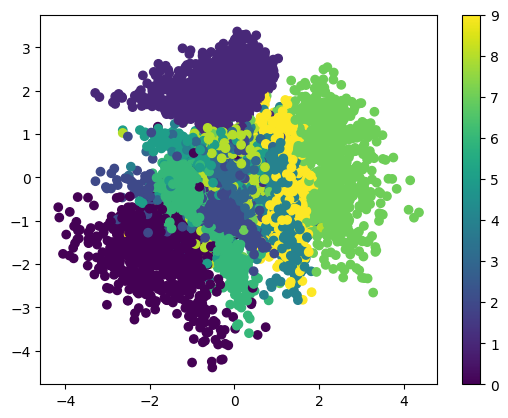

In [32]:
plt.figure()
plt.scatter(z[:, 0], z[:, 1], c=labels)
plt.colorbar()
plt.show()

### c. Create a 15x15 mesh in the 2-dimensional latent space. Use the decoder as a generator model to reconstruct handwritten digits. Combine all reconstructed digits into a 15x15 figure.

по правилу трех сигм для стандратного нормального распределния берем промежуток от -3 до 3, по формуле мю +- 3 сигма охватывает 99,7% выборки

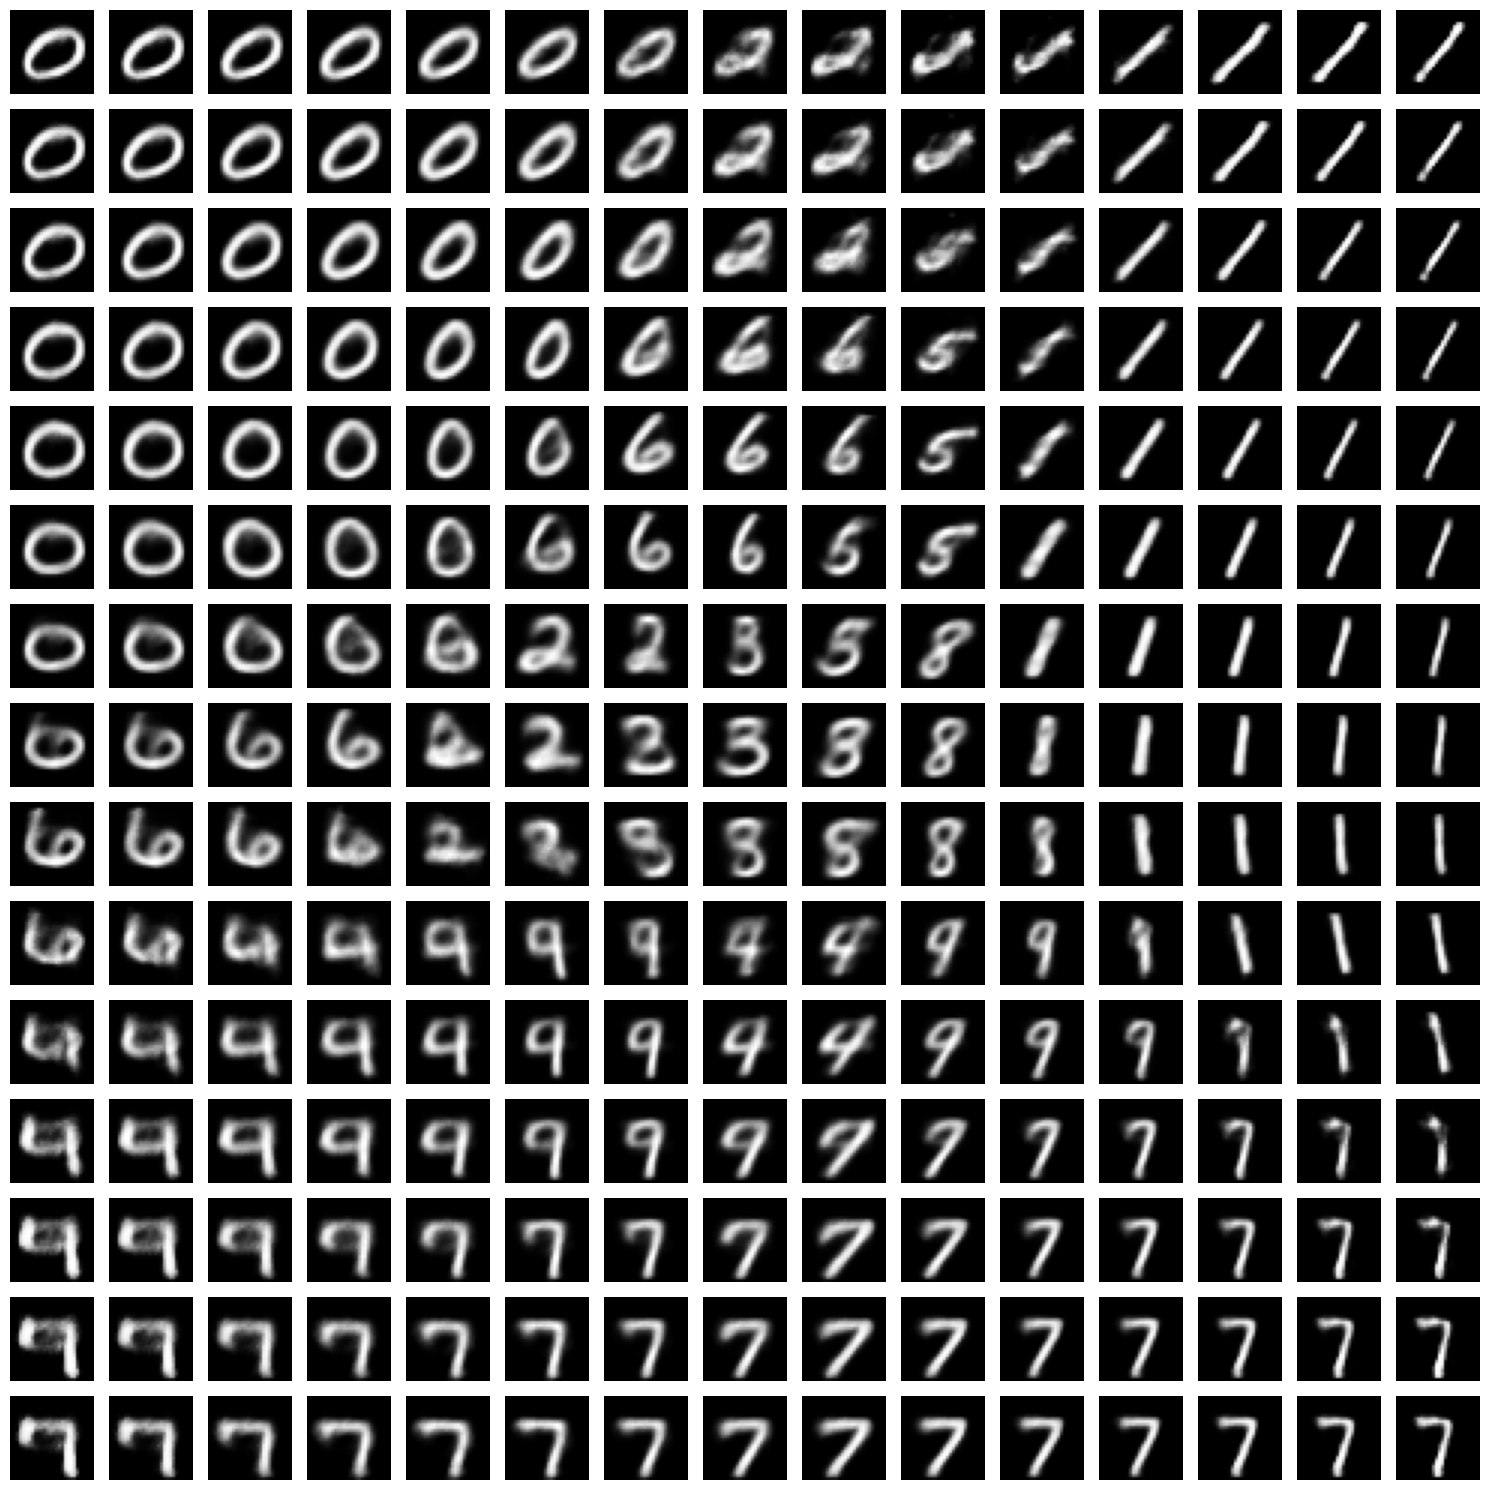

In [35]:
vae.eval()
grid = torch.linspace(-3, 3, 15)
fig, axes = plt.subplots(15, 15, figsize=(15, 15))

with torch.no_grad():
    for i, zi in enumerate(grid):
        for j, zj in enumerate(grid):
            z = torch.tensor([[zi, zj]], dtype=torch.float32)
            img = vae.decode(z).squeeze().numpy()
            axes[i, j].imshow(img, cmap='gray')
            axes[i, j].axis('off')

plt.tight_layout()
plt.show()

### d. What can you tell from the plots?

можно сказать что модель хорошо различает 1, 0, 9, 7. интересно наблюдать переходы от одной цифры к другой например от 7 к 9, или то что 6 между 0 и 9, как я понял это и есть интерполяция, то есть то, как модель распознает промежуточные значения, это можно обосновать общими паттернами которые смогла класифицировать наша модель, однако 2д пространтсва не хватает чтобы качественно все разделить